<a href="https://colab.research.google.com/github/FranciscoLopez27/acif104-brotes-eta/blob/main/notebooks/03_refinamiento_y_evaluacion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Preparación


In [1]:
import sys, os
from pathlib import Path

if "google.colab" in sys.modules:
    if not Path("acif104-brotes-eta").exists():
        !git clone https://github.com/FranciscoLopez27/acif104-brotes-eta.git
    os.chdir("acif104-brotes-eta")
    !git pull -q
    !pip -q install imbalanced-learn shap
else:
    if Path.cwd().name == "notebooks":
        os.chdir("..")

sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.getcwd())

Cloning into 'acif104-brotes-eta'...
remote: Enumerating objects: 153, done.
remote: Counting objects: 100% (153/153), done.
remote: Compressing objects: 100% (146/146), done.
remote: Total 153 (delta 39), reused 0 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (153/153), 6.08 MiB | 16.96 MiB/s, done.
Resolving deltas: 100% (39/39), done.
Carpeta de trabajo: /content/acif104-brotes-eta


## 2. Datos y configuración

In [ ]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src import datos as D, balanceo as B, evaluacion as E, modelos_ml as ML, redes as R
from src.config import CAT, NUM, AZUL, NARANJO, GRIS, VERDE, guardar, guardar_tabla

# Datos y partición de la fase 2 (entrenamiento 2012–2020, validación 2021–2022, prueba 2023–2025)
datos = D.preparar(D.cargar())
p = D.particionar(datos)
cod = D.Codificador().fit(p["tr"][CAT + NUM])
M_tr, M_va = cod.transform(p["tr"][CAT + NUM]), cod.transform(p["va"][CAT + NUM])
y_tr, y_va = p["tr"].y.values, p["va"].y.values
prep = R.PreparadorRed(cod).fit(M_tr)

# Hiperparámetros de ML elegidos en el notebook 02 (búsqueda en grilla)
PARAMS_ML = {"Regresión logística": {"C": 0.01},
             "Random Forest": {"max_depth": None, "min_samples_leaf": 5},
             "Gradient boosting": {"learning_rate": 0.03, "max_depth": 6, "l2_regularization": 1.0}}
TECNICAS = list(PARAMS_ML) + list(R.ARQUITECTURAS)
SEMILLAS = [42, 7, 123, 2024, 99]
print("Dispositivo:", R.DISPOSITIVO, "| línea base AUC-PR validación:", round(y_va.mean(), 3))

Dispositivo: cuda | línea base AUC-PR validación: 0.223


## 3. Función auxiliar para entrenar cualquier tecnica
La misma función entrena modelos de ML y redes, con cualquier balanceo y semilla, y la vamos a reutilizar en los pasos siguientes: refinamiento, umbral y sesgo de selección.

In [ ]:
def entrenar_predecir(tecnica, balanceo, semilla, M_a, y_a, M_b, y_b=None, cod_a=None, prep_a=None,
                      arq=None, opciones_red=None, epocas_fijas=None):
    """Entrena una técnica con un balanceo y una semilla en (M_a, y_a) y devuelve (probabilidades en M_b, época, modelo).

    - Redes: si y_b existe, usa parada temprana con (M_b, y_b); si se da epocas_fijas, entrena ese número de épocas.
    - cod_a / prep_a: codificador y preparador ajustados con M_a (por defecto, los de la partición principal)."""
    cod_a, prep_a = cod_a or cod, prep_a or prep
    Mb, yb, w = B.balancear(M_a, y_a, balanceo, cod_a, semilla=semilla)
    if tecnica in PARAMS_ML:
        m = ML.ajustar(ML.crear_modelo(tecnica, PARAMS_ML[tecnica], cod_a, semilla=semilla), Mb, yb, w)
        return ML.probabilidad(m, M_b), None, m
    opciones = dict(opciones_red or {})
    if epocas_fijas is not None:
        m, ep, _ = R.entrenar_red(tecnica, prep_a, Mb, yb, ponderar=(balanceo == "Ponderación de clases"),
                                  arq=arq, epocas=epocas_fijas, semilla=semilla, **opciones)
    else:
        m, ep, _ = R.entrenar_red(tecnica, prep_a, Mb, yb, M_b, y_b, ponderar=(balanceo == "Ponderación de clases"),
                                  arq=arq, semilla=semilla, **opciones)
    return R.predecir(m, *prep_a.tensores(M_b)), ep, m

## 4. Entrenamiento con 5 semillas
Se usan solo los dos escenarios de balanceo que funcionaron mejor en el notebook 02 (sin balanceo y ponderación de clases), porque SMOTE-NC y el submuestreo fueron inferiores en las seis técnicas. Son 60 entrenamientos.

In [ ]:
BAL_SEMILLAS = ["Sin balanceo", "Ponderación de clases"]
filas, probas_sem, epocas_sem = [], {}, {}
t0 = time.time()
for tecnica in TECNICAS:
    for bal in BAL_SEMILLAS:
        for s in SEMILLAS:
            pr, ep, _ = entrenar_predecir(tecnica, bal, s, M_tr, y_tr, M_va, y_va)
            probas_sem[(tecnica, bal, s)] = pr
            epocas_sem[(tecnica, bal, s)] = ep
            filas.append({"Técnica": tecnica, "Balanceo": bal, "Semilla": s,
                          "AUC-PR": E.average_precision_score(y_va, pr), "Brier": E.brier_score_loss(y_va, pr),
                          "Épocas": ep})
    print(f"{tecnica:22s} listo ({time.time() - t0:.0f} s)")
semillas_df = pd.DataFrame(filas)
guardar_tabla(semillas_df, "03_semillas_detalle")

resumen_sem = (semillas_df.groupby(["Técnica", "Balanceo"])
               .agg(AUCPR_media=("AUC-PR", "mean"), AUCPR_de=("AUC-PR", "std"),
                    AUCPR_min=("AUC-PR", "min"), AUCPR_max=("AUC-PR", "max"),
                    Brier_media=("Brier", "mean"), Epocas_media=("Épocas", "mean"))
               .reindex(pd.MultiIndex.from_product([TECNICAS, BAL_SEMILLAS])))
guardar_tabla(resumen_sem, "03_semillas_resumen")
resumen_sem.round(3)

Regresión logística    listo (1 s)
Random Forest          listo (37 s)
Gradient boosting      listo (54 s)
MLP                    listo (82 s)
MLP con embeddings     listo (131 s)
Transformer tabular    listo (243 s)


AUCPR_media  AUCPR_de  AUCPR_min  \
Regresión logística Sin balanceo                 0.494     0.000      0.494   
                    Ponderación de clases        0.495     0.000      0.495   
Random Forest       Sin balanceo                 0.617     0.003      0.614   
                    Ponderación de clases        0.631     0.004      0.626   
Gradient boosting   Sin balanceo                 0.623     0.000      0.623   
                    Ponderación de clases        0.602     0.000      0.602   
MLP                 Sin balanceo                 0.600     0.009      0.591   
                    Ponderación de clases        0.601     0.009      0.586   
MLP con embeddings  Sin balanceo                 0.587     0.017      0.569   
                    Ponderación de clases        0.586     0.023      0.561   
Transformer tabular Sin balanceo                 0.574     0.036      0.530   
                    Ponderación de clases        0.529     0.012      0.515   

                                           AUCPR_max  Brier_media  \
Regresión logística Sin balanceo               0.494        0.146   
                    Ponderación de clases      0.495        0.178   
Random Forest       Sin balanceo               0.621        0.128   
                    Ponderación de clases      0.635        0.131   
Gradient boosting   Sin balanceo               0.623        0.127   
                    Ponderación de clases      0.602        0.139   
MLP                 Sin balanceo               0.610        0.137   
                    Ponderación de clases      0.609        0.146   
MLP con embeddings  Sin balanceo               0.613        0.135   
                    Ponderación de clases      0.614        0.154   
Transformer tabular Sin balanceo               0.612        0.129   
                    Ponderación de clases      0.545        0.170   

                                           Epocas_media  
Regresión logística Sin balanceo                    NaN  
                    Ponderación de clases           NaN  
Random Forest       Sin balanceo                    NaN  
                    Ponderación de clases           NaN  
Gradient boosting   Sin balanceo                    NaN  
                    Ponderación de clases           NaN  
MLP                 Sin balanceo                   14.0  
                    Ponderación de clases          13.0  
MLP con embeddings  Sin balanceo                   34.2  
                    Ponderación de clases          29.0  
Transformer tabular Sin balanceo                   34.8  
                    Ponderación de clases          23.6

## 5. Intervalos de confianza y comparación pareada
Para cada combinación se promedian las probabilidades de las 5 semillas, que da una estimación más estable que una sola semilla, y se calcula el intervalo de confianza del 95% por bootstrap. Después, cada combinación se compara con la mejor usando la diferencia pareada: si el intervalo de la diferencia incluye 0, no se puede afirmar que la mejor sea superior.


In [ ]:
prom = {(t, b): np.mean([probas_sem[(t, b, s)] for s in SEMILLAS], axis=0) for t in TECNICAS for b in BAL_SEMILLAS}
ic = []
for (t, b), pr in prom.items():
    est, lo, hi = E.bootstrap_ic(y_va, pr)
    ic.append({"Técnica": t, "Balanceo": b, "AUC-PR": est, "IC inf": lo, "IC sup": hi})
ic_df = pd.DataFrame(ic).sort_values("AUC-PR", ascending=False).reset_index(drop=True)

mejor = (ic_df.loc[0, "Técnica"], ic_df.loc[0, "Balanceo"])
difs = []
for _, r in ic_df.iterrows():
    d, lo, hi = E.bootstrap_diferencia(y_va, prom[mejor], prom[(r["Técnica"], r["Balanceo"])])
    difs.append({"Diferencia con la mejor": d, "Dif. IC inf": lo, "Dif. IC sup": hi,
                 "¿Diferencia concluyente?": "—" if (r["Técnica"], r["Balanceo"]) == mejor else ("Sí" if lo > 0 else "No")})
ic_df = pd.concat([ic_df, pd.DataFrame(difs)], axis=1)
guardar_tabla(ic_df, "03_intervalos_confianza")
print(f"Mejor combinación (promedio de 5 semillas): {mejor[0]} + {mejor[1]}")
ic_df.round(3)

Mejor combinación (promedio de 5 semillas): Random Forest + Ponderación de clases


,Técnica,Balanceo,AUC-PR,IC inf,IC sup,Diferencia con la mejor,Dif. IC inf,Dif. IC sup,¿Diferencia concluyente?
0,Random Forest,Ponderación de clases,0.632,0.581,0.687,0.000,0.000,0.000,—
1,Gradient boosting,Sin balanceo,0.623,0.574,0.682,0.009,-0.019,0.038,No
2,Random Forest,Sin balanceo,0.618,0.566,0.672,0.014,0.002,0.025,Sí
3,MLP con embeddings,Sin balanceo,0.616,0.567,0.677,0.016,-0.016,0.046,No
4,Transformer tabular,Sin balanceo,0.613,0.560,0.669,0.019,-0.008,0.044,No
5,MLP con embeddings,Ponderación de clases,0.612,0.560,0.670,0.020,-0.010,0.050,No
6,MLP,Ponderación de clases,0.606,0.553,0.667,0.026,-0.008,0.056,No
7,MLP,Sin balanceo,0.605,0.554,0.666,0.026,-0.006,0.054,No
8,Gradient boosting,Ponderación de clases,0.602,0.551,0.662,0.030,-0.001,0.060,No
9,Transformer tabular,Ponderación de clases,0.543,0.491,0.603,0.089,0.055,0.121,Sí


## 6. Grafico de intervalos

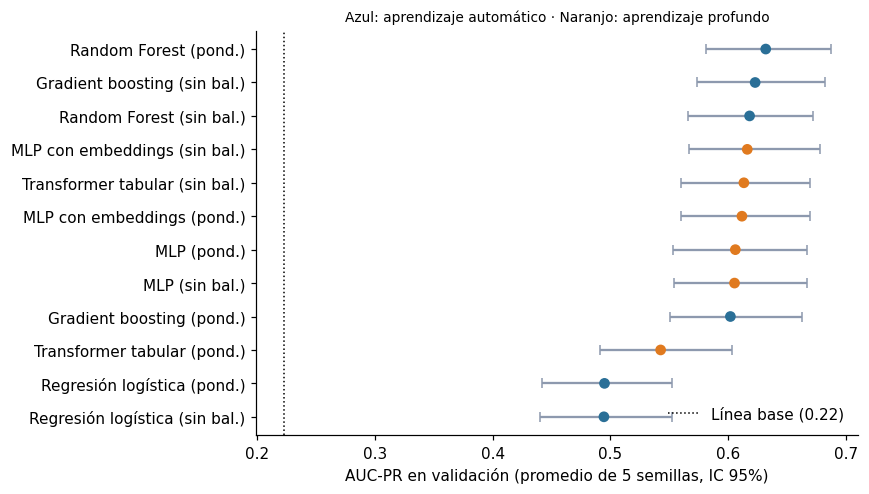

In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.6))
orden = ic_df.iloc[::-1]
colores = [AZUL if t in PARAMS_ML else NARANJO for t in orden["Técnica"]]
etiquetas = [f"{t} ({'pond.' if b.startswith('Pond') else 'sin bal.'})" for t, b in zip(orden["Técnica"], orden["Balanceo"])]
ax.errorbar(orden["AUC-PR"], range(len(orden)),
            xerr=[orden["AUC-PR"] - orden["IC inf"], orden["IC sup"] - orden["AUC-PR"]],
            fmt="none", ecolor=GRIS, capsize=3)
ax.scatter(orden["AUC-PR"], range(len(orden)), c=colores, zorder=3)
ax.set_yticks(range(len(orden)), etiquetas)
ax.axvline(y_va.mean(), color="black", ls=":", lw=1, label=f"Línea base ({y_va.mean():.2f})")
ax.set_xlabel("AUC-PR en validación (promedio de 5 semillas, IC 95%)")
ax.set_title("Azul: aprendizaje automático · Naranjo: aprendizaje profundo", fontsize=9)
ax.legend(frameon=False, loc="lower right")
guardar(fig, "fig_intervalos_confianza.png")

## 7. Refinamiento del MLP

In [ ]:
import itertools
GRILLA_MLP = {"capas": [(64,), (128, 64), (256, 128), (128, 64, 32)],
              "dropout": [0.3, 0.5],
              "weight_decay": [1e-4, 1e-2],
              "lr": [1e-3, 3e-4]}
SEMILLAS_BUSQUEDA = [42, 7, 123]

filas, t0 = [], time.time()
for capas, dropout, wd, lr in itertools.product(*GRILLA_MLP.values()):
    aps, eps = [], []
    for s in SEMILLAS_BUSQUEDA:
        pr, ep, _ = entrenar_predecir("MLP", "Sin balanceo", s, M_tr, y_tr, M_va, y_va,
                                      arq={"capas": capas, "dropout": dropout},
                                      opciones_red={"weight_decay": wd, "lr": lr})
        aps.append(E.average_precision_score(y_va, pr)); eps.append(ep)
    filas.append({"Capas": str(capas), "Dropout": dropout, "Weight decay": wd, "Tasa aprendizaje": lr,
                  "AUC-PR media": np.mean(aps), "AUC-PR DE": np.std(aps, ddof=1), "Épocas media": np.mean(eps)})
print(f"{len(filas)} configuraciones × {len(SEMILLAS_BUSQUEDA)} semillas en {time.time() - t0:.0f} s")
busqueda_mlp = pd.DataFrame(filas).sort_values(["AUC-PR media", "AUC-PR DE"], ascending=[False, True]).reset_index(drop=True)
guardar_tabla(busqueda_mlp, "03_busqueda_mlp")
busqueda_mlp.head(10).round(4)

32 configuraciones × 3 semillas en 363 s


,Capas,Dropout,Weight decay,Tasa aprendizaje,AUC-PR media,AUC-PR DE,Épocas media
0,"(128, 64, 32)",0.5,0.0100,0.0010,0.6053,0.0046,21.3333
1,"(256, 128)",0.5,0.0001,0.0010,0.6037,0.0061,15.0000
2,"(128, 64, 32)",0.5,0.0001,0.0010,0.6033,0.0072,21.3333
3,"(256, 128)",0.5,0.0100,0.0003,0.6019,0.0026,39.6667
4,"(256, 128)",0.5,0.0100,0.0010,0.6017,0.0082,15.0000
5,"(256, 128)",0.5,0.0001,0.0003,0.6017,0.0024,39.6667
6,"(128, 64, 32)",0.3,0.0100,0.0010,0.6007,0.0064,14.0000
7,"(128, 64)",0.3,0.0100,0.0010,0.6005,0.0084,14.0000
8,"(128, 64, 32)",0.3,0.0001,0.0010,0.6001,0.0071,13.0000
9,"(128, 64)",0.3,0.0001,0.0010,0.5994,0.0100,14.3333


## 8. Efecto de cada hiperparámetro

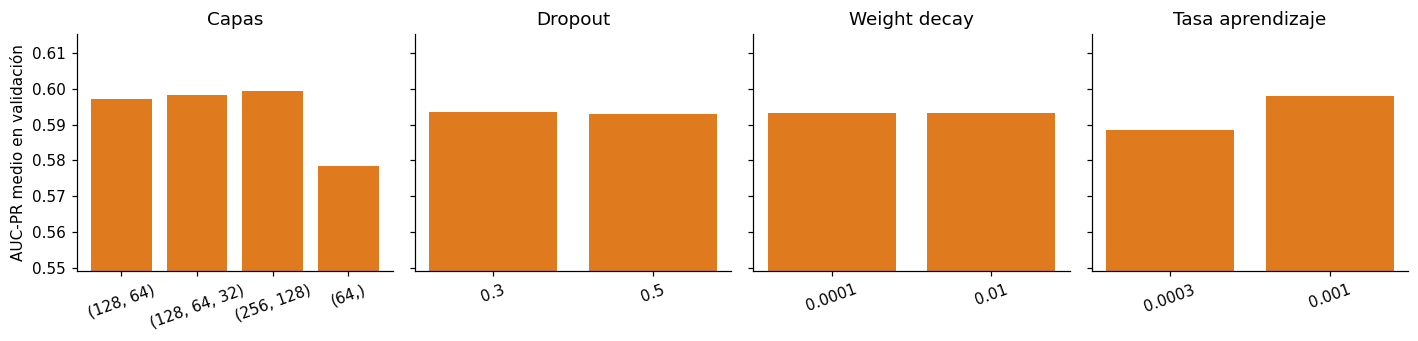

Capas             (128, 64)        0.5971
                  (128, 64, 32)    0.5982
                  (256, 128)       0.5994
                  (64,)            0.5783
Dropout           0.3              0.5936
                  0.5              0.5929
Weight decay      0.0001           0.5931
                  0.01             0.5933
Tasa aprendizaje  0.0003           0.5886
                  0.001            0.5979
Name: AUC-PR media, dtype: float64

In [ ]:
efectos = pd.concat({h: busqueda_mlp.groupby(h)["AUC-PR media"].mean() for h in ["Capas", "Dropout", "Weight decay", "Tasa aprendizaje"]})
guardar_tabla(efectos, "03_efecto_hiperparametros_mlp")

fig, axes = plt.subplots(1, 4, figsize=(13, 3.2), sharey=True)
for ax, h in zip(axes, ["Capas", "Dropout", "Weight decay", "Tasa aprendizaje"]):
    v = busqueda_mlp.groupby(h)["AUC-PR media"].mean()
    ax.bar([str(i) for i in v.index], v.values, color=NARANJO)
    ax.set_title(h)
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("AUC-PR medio en validación")
axes[0].set_ylim(busqueda_mlp["AUC-PR media"].min() - 0.01, busqueda_mlp["AUC-PR media"].max() + 0.01)
guardar(fig, "fig_efecto_hiperparametros_mlp.png")
efectos.round(4)

## 9. Aquitectura original frente a la refinada
Toma la mejor configuración, la entrena con las 5 semillas y la compara con el MLP original. La comparación usa la diferencia pareada, así que dice si la mejora es real o está dentro del margen de error.

In [ ]:
mejor_cfg = busqueda_mlp.iloc[0]
ARQ_REF = {"capas": eval(mejor_cfg["Capas"]), "dropout": float(mejor_cfg["Dropout"])}
OPC_REF = {"weight_decay": float(mejor_cfg["Weight decay"]), "lr": float(mejor_cfg["Tasa aprendizaje"])}
print("Configuración refinada:", ARQ_REF, OPC_REF)

prob_ref, ep_ref, hist_ref = {}, {}, {}
for s in SEMILLAS:
    Mb, yb, _ = B.balancear(M_tr, y_tr, "Sin balanceo", cod)
    m, ep, h = R.entrenar_red("MLP", prep, Mb, yb, M_va, y_va, arq=ARQ_REF, semilla=s, **OPC_REF)
    prob_ref[s], ep_ref[s], hist_ref[s] = R.predecir(m, *prep.tensores(M_va)), ep, h
n_param_ref = R.contar_parametros(m)

ap_orig = [E.average_precision_score(y_va, probas_sem[("MLP", "Sin balanceo", s)]) for s in SEMILLAS]
ap_ref = [E.average_precision_score(y_va, prob_ref[s]) for s in SEMILLAS]
prom_ref = np.mean([prob_ref[s] for s in SEMILLAS], axis=0)
prom_orig = prom[("MLP", "Sin balanceo")]

comparacion = pd.DataFrame({
    "MLP original (128, 64; dropout 0,3)": {"AUC-PR media (5 semillas)": np.mean(ap_orig), "AUC-PR DE": np.std(ap_orig, ddof=1),
        "AUC-PR promedio de semillas": E.average_precision_score(y_va, prom_orig),
        "Brier promedio de semillas": E.brier_score_loss(y_va, prom_orig),
        "Épocas media": np.mean([epocas_sem[("MLP", "Sin balanceo", s)] for s in SEMILLAS]), "Parámetros": 41985},
    "MLP refinado": {"AUC-PR media (5 semillas)": np.mean(ap_ref), "AUC-PR DE": np.std(ap_ref, ddof=1),
        "AUC-PR promedio de semillas": E.average_precision_score(y_va, prom_ref),
        "Brier promedio de semillas": E.brier_score_loss(y_va, prom_ref),
        "Épocas media": np.mean(list(ep_ref.values())), "Parámetros": n_param_ref}}).T
d1 = E.bootstrap_diferencia(y_va, prom_ref, prom_orig)
d2 = E.bootstrap_diferencia(y_va, prom[mejor], prom_ref)
print(f"Refinado − original: {d1[0]:+.3f} (IC 95%: {d1[1]:+.3f} a {d1[2]:+.3f})")
print(f"{mejor[0]} ({mejor[1]}) − MLP refinado: {d2[0]:+.3f} (IC 95%: {d2[1]:+.3f} a {d2[2]:+.3f})")
guardar_tabla(comparacion, "03_mlp_original_vs_refinado")
comparacion.round(4)

Configuración refinada: {'capas': (128, 64, 32), 'dropout': 0.5} {'weight_decay': 0.01, 'lr': 0.001}
Refinado − original: +0.004 (IC 95%: -0.010 a +0.016)
Random Forest (Ponderación de clases) − MLP refinado: +0.022 (IC 95%: -0.010 a +0.052)


,AUC-PR media (5 semillas),AUC-PR DE,AUC-PR promedio de semillas,Brier promedio de semillas,Épocas media,Parámetros
"MLP original (128, 64; dropout 0,3)",0.5998,0.0089,0.6052,0.1364,14.0,41985.0
MLP refinado,0.6017,0.0061,0.6095,0.1352,21.0,44033.0


## 10. Convergencia original frente a la refinada

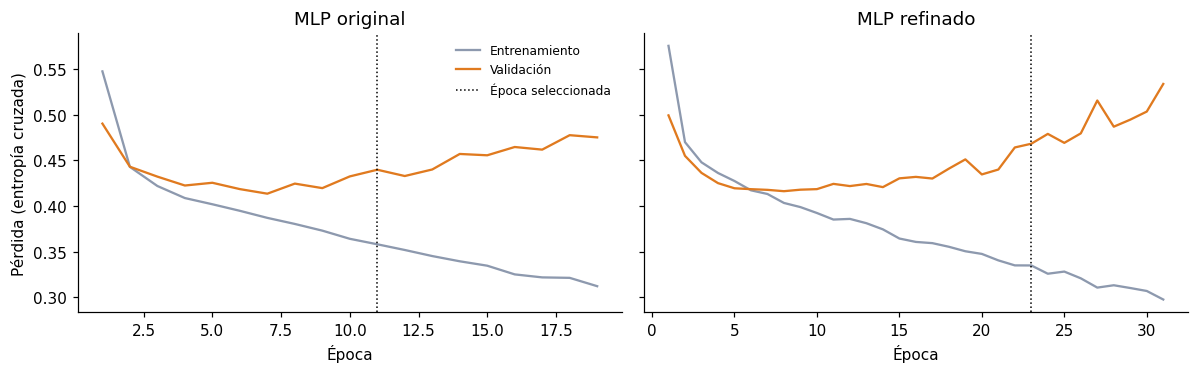

In [ ]:
Mb, yb, _ = B.balancear(M_tr, y_tr, "Sin balanceo", cod)
_, ep_o, hist_o = R.entrenar_red("MLP", prep, Mb, yb, M_va, y_va, semilla=42)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (titulo, h, ep) in zip(axes, [("MLP original", hist_o, ep_o), ("MLP refinado", hist_ref[42], ep_ref[42])]):
    ax.plot(range(1, len(h["perdida_tr"]) + 1), h["perdida_tr"], color=GRIS, label="Entrenamiento")
    ax.plot(range(1, len(h["perdida_va"]) + 1), h["perdida_va"], color=NARANJO, label="Validación")
    ax.axvline(ep, color="black", ls=":", lw=1, label="Época seleccionada")
    ax.set_title(titulo); ax.set_xlabel("Época")
axes[0].set_ylabel("Pérdida (entropía cruzada)")
axes[0].legend(frameon=False, fontsize=8)
guardar(fig, "fig_convergencia_mlp_refinado.png")

## 11. Umbral con validación cruzada temporal

In [ ]:
EPOCAS_MLP = int(round(np.mean(list(ep_ref.values()))))       # épocas fijas del MLP refinado
CANDIDATOS = {"Random Forest": "Ponderación de clases",
              "Gradient boosting": "Sin balanceo",
              "MLP refinado": "Sin balanceo",
              "Regresión logística": "Ponderación de clases"}
print("Épocas fijas del MLP refinado:", EPOCAS_MLP)

def predecir_candidato(nombre, balanceo, part):
    """Entrena un candidato con part['tr'] y devuelve sus probabilidades para el conjunto a predecir
    (part['va'] si tiene datos; si no, part['te']). Las redes promedian 5 semillas."""
    destino = part["va"] if len(part["va"]) else part["te"]
    cod_k = D.Codificador().fit(part["tr"][CAT + NUM])
    M_a, y_a = cod_k.transform(part["tr"][CAT + NUM]), part["tr"].y.values
    M_b = cod_k.transform(destino[CAT + NUM])
    if nombre == "MLP refinado":
        prep_k = R.PreparadorRed(cod_k).fit(M_a)
        prs = [entrenar_predecir("MLP", balanceo, s, M_a, y_a, M_b, cod_a=cod_k, prep_a=prep_k,
                                 arq=ARQ_REF, opciones_red=OPC_REF, epocas_fijas=EPOCAS_MLP)[0] for s in SEMILLAS]
        return np.mean(prs, axis=0), destino, None
    pr, _, modelo = entrenar_predecir(nombre, balanceo, SEMILLAS[0], M_a, y_a, M_b, cod_a=cod_k)
    return pr, destino, (modelo, cod_k)

# Predicciones fuera de muestra 2019–2022
oof = {n: [] for n in CANDIDATOS}
y_oof, anio_oof = [], []
t0 = time.time()
for k in [2019, 2020, 2021, 2022]:
    part_k = D.particionar(datos, fin_entrenamiento=k - 1, fin_validacion=k)
    for nombre, bal in CANDIDATOS.items():
        pr, destino, _ = predecir_candidato(nombre, bal, part_k)
        oof[nombre].append(pr)
    y_oof.append(destino.y.values); anio_oof.append(destino["Año estadistico"].values)
    print(f"Año {k} listo ({time.time() - t0:.0f} s)")
y_oof, anio_oof = np.concatenate(y_oof), np.concatenate(anio_oof)
oof = {n: np.concatenate(v) for n, v in oof.items()}

umbrales, filas = {}, []
for nombre in CANDIDATOS:
    u = E.umbral_para_recall(y_oof, oof[nombre], 0.70)
    umbrales[nombre] = u
    est, lo, hi = E.bootstrap_ic(y_oof, oof[nombre])
    filas.append({"Candidato": nombre, "Balanceo": CANDIDATOS[nombre], "AUC-PR (VC temporal)": est,
                  "IC inf": lo, "IC sup": hi, **E.metricas(y_oof, oof[nombre], u)})
vc_df = pd.DataFrame(filas)
guardar_tabla(vc_df, "03_validacion_cruzada_temporal")
print(f"Brotes fuera de muestra: {len(y_oof)} | positivos: {y_oof.sum()} | prevalencia: {y_oof.mean():.3f}")
vc_df.round(3)

Épocas fijas del MLP refinado: 21
Año 2019 listo (16 s)
Año 2020 listo (31 s)
Año 2021 listo (50 s)
Año 2022 listo (67 s)
Brotes fuera de muestra: 3259 | positivos: 696 | prevalencia: 0.214


,Candidato,Balanceo,AUC-PR (VC temporal),IC inf,IC sup,AUC-PR,AUC-ROC,Recall,Precisión,F1,Exactitud bal.,Brier,Umbral
0,Random Forest,Ponderación de clases,0.542,0.502,0.581,0.542,0.819,0.701,0.463,0.557,0.740,0.142,0.397
1,Gradient boosting,Sin balanceo,0.515,0.475,0.554,0.515,0.797,0.701,0.432,0.535,0.726,0.136,0.183
2,MLP refinado,Sin balanceo,0.512,0.471,0.549,0.512,0.797,0.701,0.424,0.528,0.721,0.138,0.153
3,Regresión logística,Ponderación de clases,0.453,0.417,0.489,0.453,0.775,0.701,0.387,0.498,0.700,0.195,0.463


## 12. Modelos finales y evaluación en prueba
Cada candidato se reentrena con 2012–2022 y se evalúa una sola vez en prueba. La tabla también muestra qué habría pasado con el criterio de la fase 2 (umbral de máximo F1 elegido en validación), para comparar ambos métodos.

In [ ]:
part_f = D.particionar(datos, fin_entrenamiento=2022, fin_validacion=2022)   # entrenamiento 2012–2022, prueba 2023–2025
y_te = part_f["te"].y.values
probas_te, finales = {}, {}
for nombre, bal in CANDIDATOS.items():
    probas_te[nombre], _, finales[nombre] = predecir_candidato(nombre, bal, part_f)

# Umbral "estilo fase 2": máximo F1 sobre las probabilidades de validación (modelos entrenados hasta 2020)
prob_val_fase2 = {"Random Forest": prom[("Random Forest", "Ponderación de clases")],
                  "Gradient boosting": prom[("Gradient boosting", "Sin balanceo")],
                  "MLP refinado": prom_ref,
                  "Regresión logística": prom[("Regresión logística", "Ponderación de clases")]}

filas = []
for nombre in CANDIDATOS:
    pr = probas_te[nombre]
    est, lo, hi = E.bootstrap_ic(y_te, pr)
    m_nuevo = E.metricas(y_te, pr, umbrales[nombre])
    m_f2 = E.metricas(y_te, pr, E.umbral_f1(y_va, prob_val_fase2[nombre]))
    filas.append({"Candidato": nombre, "AUC-PR": est, "IC inf": lo, "IC sup": hi, "AUC-ROC": m_nuevo["AUC-ROC"],
                  "Brier": m_nuevo["Brier"], "Umbral": m_nuevo["Umbral"], "Recall": m_nuevo["Recall"],
                  "Precisión": m_nuevo["Precisión"], "F1": m_nuevo["F1"], "Exactitud bal.": m_nuevo["Exactitud bal."],
                  "Recall (umbral fase 2)": m_f2["Recall"], "Precisión (umbral fase 2)": m_f2["Precisión"]})
prueba_df = pd.DataFrame(filas).sort_values("AUC-PR", ascending=False).reset_index(drop=True)
guardar_tabla(prueba_df, "03_prueba_final")
print(f"Prueba: {len(y_te)} brotes | positivos: {y_te.sum()} | línea base AUC-PR: {y_te.mean():.3f}")
prueba_df.round(3)

Prueba: 4493 brotes | positivos: 797 | línea base AUC-PR: 0.177


,Candidato,AUC-PR,IC inf,IC sup,AUC-ROC,Brier,Umbral,Recall,Precisión,F1,Exactitud bal.,Recall (umbral fase 2),Precisión (umbral fase 2)
0,Random Forest,0.499,0.467,0.537,0.835,0.129,0.397,0.715,0.429,0.536,0.755,0.773,0.403
1,Gradient boosting,0.490,0.457,0.529,0.820,0.118,0.183,0.716,0.386,0.501,0.735,0.754,0.366
2,MLP refinado,0.445,0.410,0.483,0.769,0.130,0.153,0.448,0.413,0.430,0.655,0.472,0.383
3,Regresión logística,0.422,0.394,0.459,0.814,0.182,0.463,0.802,0.356,0.493,0.744,0.738,0.384


## 13. Determinar si el mejor es realmente el mejor en prueba

In [ ]:
mejor_te = prueba_df.loc[0, "Candidato"]
dif = []
for nombre in prueba_df["Candidato"][1:]:
    d, lo, hi = E.bootstrap_diferencia(y_te, probas_te[mejor_te], probas_te[nombre])
    dif.append({"Comparación": f"{mejor_te} − {nombre}", "Diferencia AUC-PR": d, "IC inf": lo, "IC sup": hi,
                "¿Concluyente?": "Sí" if lo > 0 else "No"})
dif_te = pd.DataFrame(dif)
guardar_tabla(dif_te, "03_prueba_diferencias")
dif_te.round(3)

,Comparación,Diferencia AUC-PR,IC inf,IC sup,¿Concluyente?
0,Random Forest − Gradient boosting,0.009,-0.012,0.029,No
1,Random Forest − MLP refinado,0.054,0.031,0.076,Sí
2,Random Forest − Regresión logística,0.077,0.052,0.100,Sí


## 14. Curva precision-exhaustividad en prueba
Cada punto marca dónde queda el modelo con el umbral elegido. La línea vertical discontinua marca la exhaustividad de 0,70 que exige RNF05.

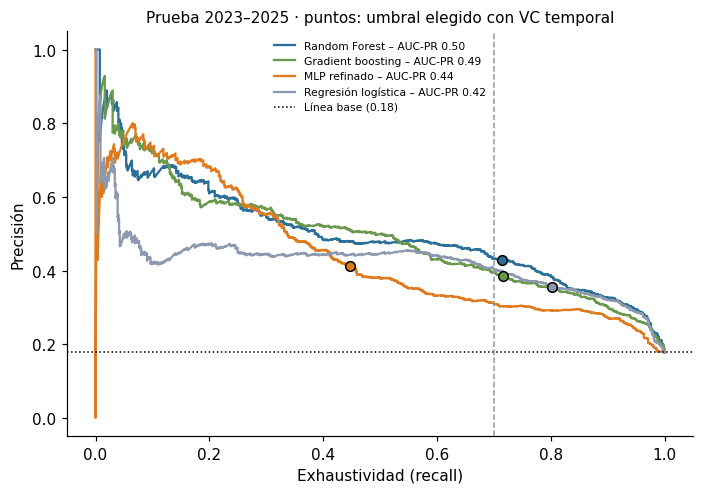

In [ ]:
fig, ax = plt.subplots(figsize=(6.5, 4.6))
for nombre, color in zip(CANDIDATOS, [AZUL, VERDE, NARANJO, GRIS]):
    prec, rec, _ = E.precision_recall_curve(y_te, probas_te[nombre])
    fila = prueba_df.set_index("Candidato").loc[nombre]
    ax.plot(rec, prec, color=color, label=f"{nombre} – AUC-PR {fila['AUC-PR']:.2f}")
    ax.scatter(fila["Recall"], fila["Precisión"], color=color, edgecolor="black", zorder=3, s=40)
ax.axhline(y_te.mean(), color="black", ls=":", lw=1, label=f"Línea base ({y_te.mean():.2f})")
ax.axvline(0.70, color=GRIS, ls="--", lw=1)
ax.set_xlabel("Exhaustividad (recall)"); ax.set_ylabel("Precisión")
ax.set_title("Prueba 2023–2025 · puntos: umbral elegido con VC temporal", fontsize=10)
ax.legend(fontsize=7, frameon=False)
guardar(fig, "fig_curvas_pr_prueba.png")

## 15. Desempeño por año del mejor modelo

In [ ]:
anios = part_f["te"]["Año estadistico"].values
por_anio = []
for a in sorted(set(anios)):
    i = anios == a
    m = E.metricas(y_te[i], probas_te[mejor_te][i], umbrales[mejor_te])
    por_anio.append({"Año": a, "Brotes": int(i.sum()), "Prevalencia": y_te[i].mean(), "AUC-PR": m["AUC-PR"],
                     "Recall": m["Recall"], "Precisión": m["Precisión"]})
por_anio_df = pd.DataFrame(por_anio)
guardar_tabla(por_anio_df, "03_prueba_por_anio")
print("Modelo:", mejor_te)
por_anio_df.round(3)

Modelo: Random Forest


,Año,Brotes,Prevalencia,AUC-PR,Recall,Precisión
0,2023,1400,0.140,0.508,0.730,0.393
1,2024,1526,0.193,0.606,0.834,0.505
2,2025,1567,0.195,0.392,0.592,0.379


## 16. Sesgo de selección
Se entrena el mismo Random Forest con todos los brotes con diagnóstico, sin filtrar por conclusión, y se comparan los dos modelos en tres conjuntos de prueba. Un detalle técnico: para que la comparación sea justa, cada modelo recibe la tasa histórica regional calculada igual que en su entrenamiento.

In [ ]:
modelo_conf, cod_conf = finales["Random Forest"]                 # modelo final (entrenado con confirmados)

datos_todos = D.preparar(D.cargar(), solo_confirmados=False)       # todos los brotes con diagnóstico
part_todos = D.particionar(datos_todos, fin_entrenamiento=2022, fin_validacion=2022)
te_todos = part_todos["te"].copy()
print("Prueba con todos los brotes:", len(te_todos), "| no confirmados:", (te_todos.conclusion != "Realizada, se confirma").sum())
print("Entrenamiento 2012–2022:", part_todos["tr"].conclusion.value_counts().to_dict())
print("Prueba 2023–2025:", te_todos.conclusion.value_counts().to_dict())

TASA_CONF = datos.groupby(["Región de consumo", "Año estadistico"])["tasa_hist_region"].first()

def ajustar_categorias(df, cod_ref, usar_tasa_confirmados=False):
    """Agrupa las comunas y alimentos que el codificador de referencia no conoce (como en su entrenamiento).
    Con usar_tasa_confirmados=True, la tasa histórica regional se calcula como en el modelo de confirmados."""
    df = df.copy()
    if usar_tasa_confirmados:
        clave = pd.MultiIndex.from_arrays([df["Región de consumo"], df["Año estadistico"]])
        df["tasa_hist_region"] = TASA_CONF.reindex(clave).values
    conocidas_com = set(cod_ref.enc.categories_[CAT.index("comuna de consumo")])
    conocidas_ali = set(cod_ref.enc.categories_[CAT.index("Alimento Sospechoso")])
    df["comuna de consumo"] = df["comuna de consumo"].where(df["comuna de consumo"].isin(conocidas_com), "Otra comuna")
    df["Alimento Sospechoso"] = df["Alimento Sospechoso"].where(df["Alimento Sospechoso"].isin(conocidas_ali), "Otro alimento")
    return df

# Modelo alternativo entrenado con todos los brotes con diagnóstico (2012–2022), con su propio umbral por VC temporal
oof_t, y_oof_t = [], []
for k in [2019, 2020, 2021, 2022]:
    pr, destino, _ = predecir_candidato("Random Forest", "Ponderación de clases",
                                        D.particionar(datos_todos, fin_entrenamiento=k - 1, fin_validacion=k))
    oof_t.append(pr); y_oof_t.append(destino.y.values)
umbral_todos = E.umbral_para_recall(np.concatenate(y_oof_t), np.concatenate(oof_t), 0.70)
_, _, (modelo_todos, cod_todos) = predecir_candidato("Random Forest", "Ponderación de clases", part_todos)

conjuntos = {"Prueba: solo confirmados": te_todos[te_todos.conclusion == "Realizada, se confirma"],
             "Prueba: todos con diagnóstico": te_todos,
             "Prueba: solo no confirmados": te_todos[te_todos.conclusion != "Realizada, se confirma"]}
filas = []
for nombre_conj, df_c in conjuntos.items():
    for nombre_mod, modelo, cod_m, u in [("Entrenado con confirmados", modelo_conf, cod_conf, umbrales["Random Forest"]),
                                          ("Entrenado con todos", modelo_todos, cod_todos, umbral_todos)]:
        M_c = cod_m.transform(ajustar_categorias(df_c, cod_m, usar_tasa_confirmados=(modelo is modelo_conf))[CAT + NUM])
        pr = ML.probabilidad(modelo, M_c)
        m = E.metricas(df_c.y.values, pr, u)
        filas.append({"Conjunto": nombre_conj, "Modelo": nombre_mod, "Brotes": len(df_c),
                      "Prevalencia": df_c.y.mean(), "AUC-PR": m["AUC-PR"], "Recall": m["Recall"],
                      "Precisión": m["Precisión"], "Brier": m["Brier"], "Prob. media": pr.mean()})
sesgo_df = pd.DataFrame(filas)
guardar_tabla(sesgo_df, "03_sesgo_seleccion")
sesgo_df.round(3)

Prueba con todos los brotes: 4551 | no confirmados: 58
Entrenamiento 2012–2022: {'Realizada, se confirma': 9751, 'Sin conclusión': 355, 'Realizada, se descarta': 187, 'Otros resultados': 162, 'Realizada, en estudio': 63}
Prueba 2023–2025: {'Realizada, se confirma': 4493, 'Realizada, se descarta': 58}


,Conjunto,Modelo,Brotes,Prevalencia,AUC-PR,Recall,Precisión,Brier,Prob. media
0,Prueba: solo confirmados,Entrenado con confirmados,4493,0.177,0.499,0.715,0.429,0.129,0.296
1,Prueba: solo confirmados,Entrenado con todos,4493,0.177,0.509,0.758,0.423,0.127,0.298
2,Prueba: todos con diagnóstico,Entrenado con confirmados,4551,0.177,0.492,0.712,0.421,0.130,0.297
3,Prueba: todos con diagnóstico,Entrenado con todos,4551,0.177,0.502,0.756,0.417,0.129,0.299
4,Prueba: solo no confirmados,Entrenado con confirmados,58,0.155,0.180,0.444,0.114,0.232,0.427
5,Prueba: solo no confirmados,Entrenado con todos,58,0.155,0.205,0.556,0.152,0.219,0.415


## 17. SHAP, importancia global
SHAP descompone cada predicción en la contribución de cada variable. Se calcula sobre 600 brotes de prueba con TreeExplainer, que es exacto para modelos de árboles. Puede tardar unos minutos, porque el bosque tiene 400 árboles sin límite de profundidad.

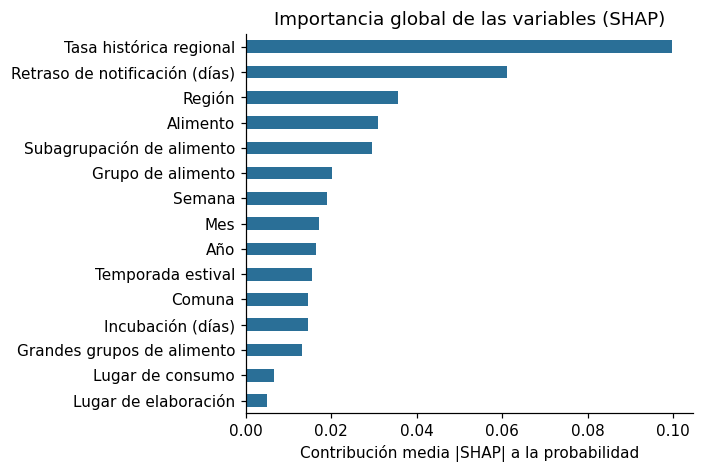

,0
Tasa histórica regional,0.0997
Retraso de notificación (días),0.0612
Región,0.0356
Alimento,0.0308
Subagrupación de alimento,0.0294
Grupo de alimento,0.0201
Semana,0.0190
Mes,0.0172
Año,0.0164
Temporada estival,0.0154


In [ ]:
import shap
te_f = part_f["te"]
M_te = cod_conf.transform(te_f[CAT + NUM])
NOMBRES = ["Región", "Comuna", "Lugar de elaboración", "Lugar de consumo", "Grupo de alimento", "Alimento",
           "Subagrupación de alimento", "Grandes grupos de alimento", "Año", "Incubación (días)",
           "Retraso de notificación (días)", "Mes", "Semana", "Temporada estival", "Tasa histórica regional"]

rng = np.random.default_rng(42)
idx = rng.choice(len(te_f), size=600, replace=False)
explainer = shap.TreeExplainer(modelo_conf)
sv = explainer.shap_values(M_te[idx], check_additivity=False)
sv = sv[1] if isinstance(sv, list) else (sv[:, :, 1] if sv.ndim == 3 else sv)   # contribuciones a la clase "específico"
base = explainer.expected_value
base = float(base[1]) if np.ndim(base) else float(base)

imp_shap = pd.Series(np.abs(sv).mean(axis=0), index=NOMBRES).sort_values(ascending=False)
guardar_tabla(imp_shap, "03_shap_importancia")

fig, ax = plt.subplots(figsize=(6.5, 4.4))
imp_shap.iloc[::-1].plot.barh(ax=ax, color=AZUL)
ax.set_xlabel("Contribución media |SHAP| a la probabilidad")
ax.set_title("Importancia global de las variables (SHAP)")
guardar(fig, "fig_shap_importancia.png")
imp_shap.round(4)

## 18. SHAP, grafico de enjambre
Cada punto es un brote. La posición horizontal indica si esa variable sube (derecha) o baja (izquierda) su probabilidad, y el color indica si el valor de la variable es alto (rojo) o bajo (azul).

/tmp/ipykernel_1910/1667616521.py:2: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(sv, X_muestra, show=False, max_display=12)


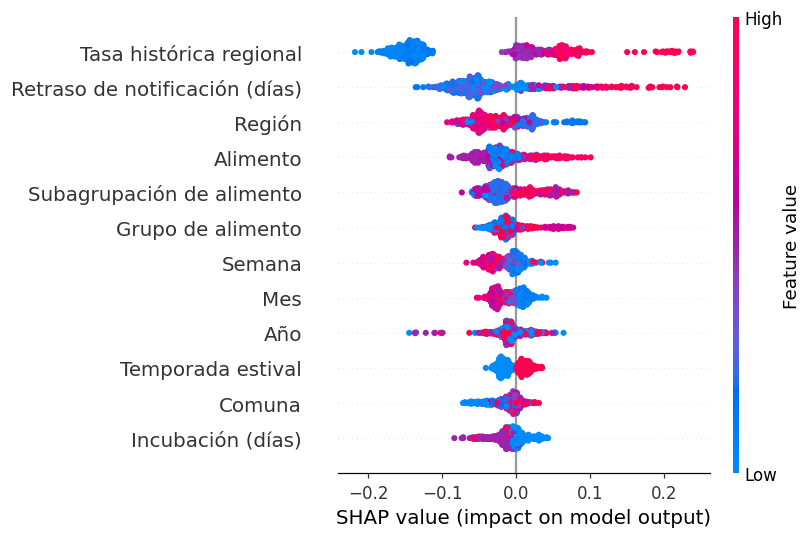

In [ ]:
X_muestra = pd.DataFrame(M_te[idx], columns=NOMBRES)
shap.summary_plot(sv, X_muestra, show=False, max_display=12)
fig = plt.gcf(); fig.set_size_inches(7.5, 5)
guardar(fig, "fig_shap_enjambre.png")

## 19. SHAP, casos particulares
Explica dos brotes concretos: uno con probabilidad alta que efectivamente llegó a diagnóstico específico y uno con probabilidad baja que quedó inespecífico. La rúbrica pide explícitamente “casos particulares”.

caso_alto: probabilidad 0.93 | diagnóstico real: específico | Envenenamiento escombroideo por pescado


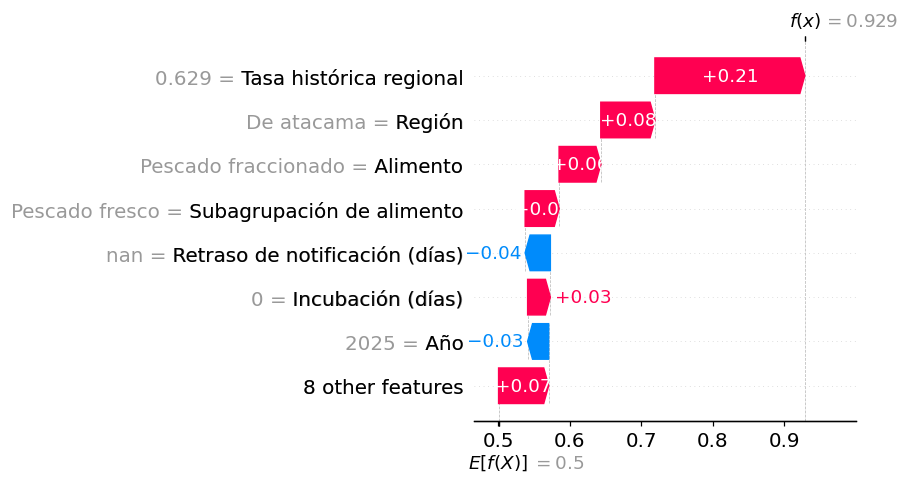

caso_bajo: probabilidad 0.01 | diagnóstico real: inespecífico | Diagnostico inespecifico


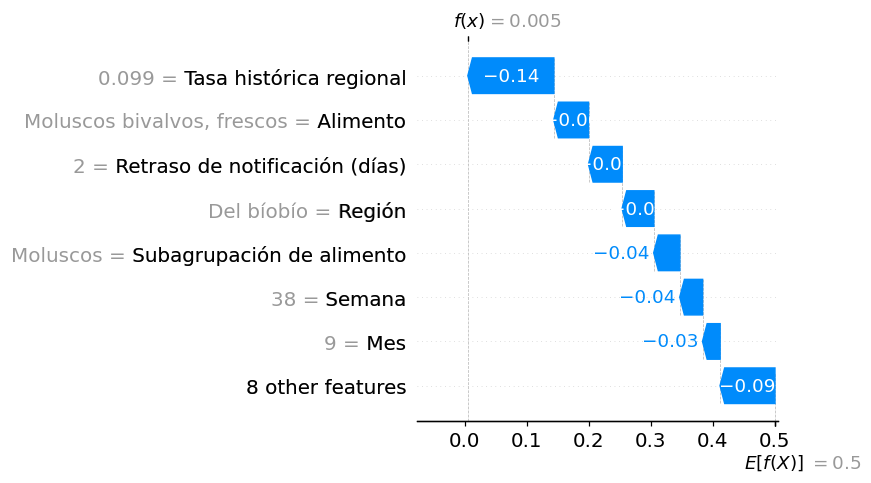

In [ ]:
pr_muestra = ML.probabilidad(modelo_conf, M_te[idx])
y_muestra = te_f.y.values[idx]
caso_alto = int(np.argmax(np.where(y_muestra == 1, pr_muestra, -1)))
caso_bajo = int(np.argmin(np.where(y_muestra == 0, pr_muestra, 2)))

for titulo, i in [("caso_alto", caso_alto), ("caso_bajo", caso_bajo)]:
    fila = te_f.iloc[idx[i]]
    datos_caso = [fila["Región de consumo"], fila["comuna de consumo"], fila["Local de elaboración"],
                  fila["Local consumo"], fila["Grupo Alimento Sospechoso"], fila["Alimento Sospechoso"],
                  fila["Sub agrupación alimento sospechoso"], fila["Grandes grupos alimentos sospechoso"],
                  int(fila["Año estadistico"]), fila["incubacion"], fila["retraso_notif"], int(fila["mes"]),
                  int(fila["Semana estadistica"]), int(fila["temporada_estival"]), round(fila["tasa_hist_region"], 3)]
    print(f"{titulo}: probabilidad {pr_muestra[i]:.2f} | diagnóstico real: {'específico' if y_muestra[i] else 'inespecífico'}"
          f" | {fila['Diagnostico agrupado']}")
    expl = shap.Explanation(values=sv[i], base_values=base, data=np.array(datos_caso, dtype=object), feature_names=NOMBRES)
    shap.plots.waterfall(expl, max_display=8, show=False)
    fig = plt.gcf(); fig.set_size_inches(8, 4.5)
    guardar(fig, f"fig_shap_{titulo}.png")

## 20. Probabilidad con dos escenarios

Nivel de referencia (P75 de la tasa histórica regional): 0.256


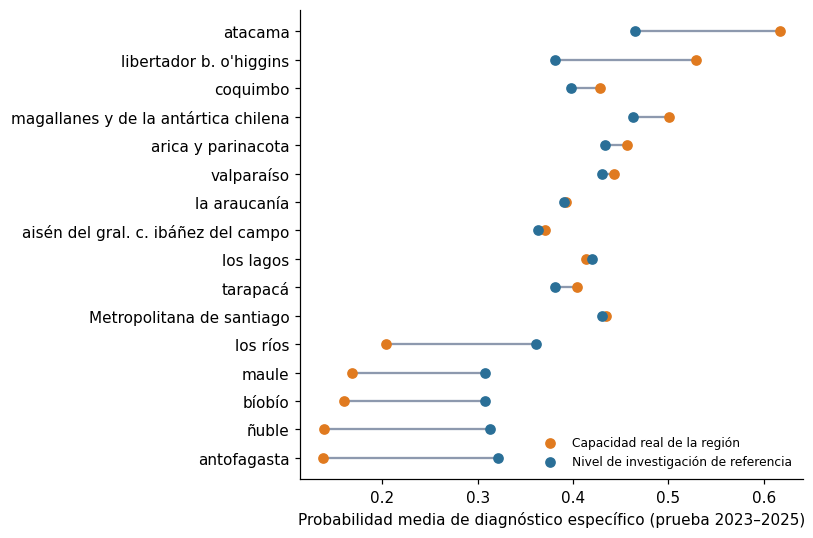

,Tasa histórica,Prob. capacidad real,Prob. referencia,Diferencia
Región,,,,
De antofagasta,0.074,0.138,0.322,0.184
De ñuble,0.077,0.139,0.312,0.174
Del bíobío,0.090,0.160,0.308,0.148
Del maule,0.114,0.169,0.307,0.139
De los ríos,0.124,0.204,0.361,0.157
Metropolitana de santiago,0.206,0.434,0.430,-0.004
De tarapacá,0.214,0.404,0.381,-0.022
De los lagos,0.236,0.414,0.420,0.006
De aisén del gral. c. ibáñez del campo,0.237,0.370,0.363,-0.007


In [ ]:
j = cod_conf.columna("tasa_hist_region")
referencia = float(np.percentile(part_f["tr"]["tasa_hist_region"], 75))
M_ref = M_te.copy(); M_ref[:, j] = referencia
p_real = ML.probabilidad(modelo_conf, M_te)
p_ref = ML.probabilidad(modelo_conf, M_ref)
print(f"Nivel de referencia (P75 de la tasa histórica regional): {referencia:.3f}")

escenarios = (pd.DataFrame({"Región": te_f["Región de consumo"].values, "Tasa histórica": te_f["tasa_hist_region"].values,
                            "Prob. capacidad real": p_real, "Prob. referencia": p_ref})
              .groupby("Región").mean().sort_values("Tasa histórica"))
escenarios["Diferencia"] = escenarios["Prob. referencia"] - escenarios["Prob. capacidad real"]
guardar_tabla(escenarios, "03_probabilidad_dos_escenarios")

fig, ax = plt.subplots(figsize=(7.5, 5))
y_pos = np.arange(len(escenarios))
ax.hlines(y_pos, escenarios["Prob. capacidad real"], escenarios["Prob. referencia"], color=GRIS)
ax.scatter(escenarios["Prob. capacidad real"], y_pos, color=NARANJO, label="Capacidad real de la región", zorder=3)
ax.scatter(escenarios["Prob. referencia"], y_pos, color=AZUL, label="Nivel de investigación de referencia", zorder=3)
ax.set_yticks(y_pos, escenarios.index.str.replace("De ", "").str.replace("Del ", ""))
ax.set_xlabel("Probabilidad media de diagnóstico específico (prueba 2023–2025)")
ax.legend(frameon=False, fontsize=8, loc="lower right")
guardar(fig, "fig_dos_escenarios.png")
escenarios.round(3)

## 21. Desempeño por región

In [2]:
# Desempeño del modelo final por región (RNF05) y análisis de la caída de 2025
import numpy as np, pandas as pd
from src import datos as D, balanceo as B, evaluacion as E, modelos_ml as ML
from src.config import CAT, NUM, guardar_tabla

UMBRAL = 0.397                                                        # umbral elegido con validación cruzada temporal
datos = D.preparar(D.cargar())
part_f = D.particionar(datos, fin_entrenamiento=2022, fin_validacion=2022)
cod_f = D.Codificador().fit(part_f["tr"][CAT + NUM])
Mb, yb, w = B.balancear(cod_f.transform(part_f["tr"][CAT + NUM]), part_f["tr"].y.values, "Ponderación de clases", cod_f, semilla=42)
rf = ML.ajustar(ML.crear_modelo("Random Forest", {"max_depth": None, "min_samples_leaf": 5}, cod_f, semilla=42), Mb, yb, w)

te = part_f["te"].copy()
te["prob"] = ML.probabilidad(rf, cod_f.transform(te[CAT + NUM]))
print("Control, AUC-PR total en prueba:", round(E.metricas(te.y.values, te.prob.values, UMBRAL)["AUC-PR"], 3))  # debe dar 0.499

def resumen(g):
    """Métricas de un grupo de brotes con el umbral fijo."""
    marcados = g.prob >= UMBRAL
    return pd.Series({"Brotes": len(g), "Específicos": int(g.y.sum()), "% específico": 100 * g.y.mean(),
                      "Tasa histórica": g.tasa_hist_region.mean(),
                      "AUC-PR": E.average_precision_score(g.y, g.prob) if g.y.nunique() > 1 else np.nan,
                      "Recall": (marcados & (g.y == 1)).sum() / g.y.sum() if g.y.sum() else np.nan,
                      "% marcados": 100 * marcados.mean()})

por_region = te.groupby("Región de consumo").apply(resumen).sort_values("Brotes", ascending=False)
guardar_tabla(por_region, "03_prueba_por_region")
region_2025 = (te.groupby(["Región de consumo", "Año estadistico"]).apply(resumen)
                 .reset_index().pivot(index="Región de consumo", columns="Año estadistico", values=["Específicos", "Recall"]))
guardar_tabla(region_2025, "03_recall_region_anio")
display(por_region.round(3)); display(region_2025.round(3))

Control, AUC-PR total en prueba: 0.499


/tmp/ipykernel_594/1626930976.py:26: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  por_region = te.groupby("Región de consumo").apply(resumen).sort_values("Brotes", ascending=False)
/tmp/ipykernel_594/1626930976.py:28: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  region_2025 = (te.groupby(["Región de consumo", "Año estadistico"]).apply(resumen)


,Brotes,Específicos,% específico,Tasa histórica,AUC-PR,Recall,% marcados
Región de consumo,,,,,,,
Del bíobío,1321.0,55.0,4.164,0.090,0.587,0.618,6.056
Metropolitana de santiago,525.0,192.0,36.571,0.206,0.589,0.714,49.333
De coquimbo,468.0,216.0,46.154,0.350,0.541,0.727,60.897
Del maule,409.0,14.0,3.423,0.114,0.142,0.357,5.379
De ñuble,285.0,10.0,3.509,0.077,0.087,0.000,1.404
De valparaíso,272.0,85.0,31.250,0.284,0.725,0.894,56.985
De antofagasta,259.0,13.0,5.019,0.074,0.198,0.077,0.386
De arica y parinacota,239.0,58.0,24.268,0.326,0.426,0.672,55.230
De tarapacá,234.0,38.0,16.239,0.214,0.304,0.737,46.581


Específicos              Recall  \
Año estadistico                                2023  2024   2025   2023   
Región de consumo                                                         
De aisén del gral. c. ibáñez del campo          0.0   2.0    1.0    NaN   
De antofagasta                                  4.0   4.0    5.0  0.250   
De arica y parinacota                          16.0  15.0   27.0  0.875   
De atacama                                      3.0  15.0   15.0  1.000   
De coquimbo                                    33.0  77.0  106.0  0.667   
De la araucanía                                 1.0   9.0    4.0  1.000   
De los lagos                                    2.0  13.0    8.0  1.000   
De los ríos                                     5.0   3.0    2.0  0.200   
De magallanes y de la antártica chilena         5.0   3.0    4.0  1.000   
De tarapacá                                    13.0   8.0   17.0  0.769   
De valparaíso                                  22.0  42.0   21.0  0.909   
De ñuble                                        2.0   4.0    4.0  0.000   
Del bíobío                                     21.0  21.0   13.0  0.476   
Del libertador b. o'higgins                     5.0   7.0    9.0  0.800   
Del maule                                       8.0   3.0    3.0  0.375   
Metropolitana de santiago                      56.0  69.0   67.0  0.839   

                                                       
Año estadistico                           2024   2025  
Región de consumo                                      
De aisén del gral. c. ibáñez del campo   1.000  0.000  
De antofagasta                           0.000  0.000  
De arica y parinacota                    0.867  0.444  
De atacama                               1.000  1.000  
De coquimbo                              0.857  0.651  
De la araucanía                          0.889  0.750  
De los lagos                             0.615  0.625  
De los ríos                              0.333  0.000  
De magallanes y de la antártica chilena  1.000  0.750  
De tarapacá                              0.875  0.647  
De valparaíso                            0.952  0.762  
De ñuble                                 0.000  0.000  
Del bíobío                               0.667  0.769  
Del libertador b. o'higgins              1.000  0.889  
Del maule                                0.667  0.000  
Metropolitana de santiago                0.870  0.448